# LLM Fine Tuning · Lesson 2 · Choose a base model that fits

Lesson 1 decided *whether* to fine-tune. This lab decides *what to fine-tune*. Four questions are asked in order, and
each one can rule a candidate out:

1. **May we use it?** Licence and access.
2. **Will it fit on our GPU for training?** Predicted memory, then measured memory, for full fine-tuning, LoRA and QLoRA.
3. **What does our language cost?** Tokens per sentence in four languages, for seven tokenizers.
4. **Is it good enough, and fast enough?** Accuracy and latency before any training, by model size.

Everything runs on a free Colab T4 with open models that need no access token.

**Run it:** Runtime → Change runtime type → T4 GPU, then Runtime → Run all (about 20 minutes, most of it downloads).
The lesson that explains every result is at [docs.recohut.com](https://docs.recohut.com/courses/llm-fine-tuning/1-decide/02-choose-a-base-model).

## 0. Install and check the GPU

In [1]:
# Pinned versions, so the code matches the lesson it was written for.
%pip install -q transformers==4.51.3 peft==0.15.2 accelerate==1.6.0 bitsandbytes==0.50.2

pip may report dependency conflicts with packages Colab preinstalls, such as `gradio`. This lab does not use them,
so the warning can be ignored.

In [2]:
import gc
import json
import re
import time

import matplotlib.pyplot as plt
import pandas as pd
import torch
import transformers
from huggingface_hub import model_info
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import AutoConfig, AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig, set_seed

set_seed(42)
%config InlineBackend.figure_formats = ['svg']
assert torch.cuda.is_available(), "Choose Runtime -> Change runtime type -> T4 GPU."

GPU_GB = torch.cuda.get_device_properties(0).total_memory / 1e9
major, minor = torch.cuda.get_device_capability()
print(f"GPU: {torch.cuda.get_device_name(0)}, {GPU_GB:.1f} GB, compute capability {major}.{minor}")
# bfloat16 tensor cores arrived with compute capability 8.0 (Ampere). A T4 (7.5) trains in float16 instead.
DTYPE = torch.bfloat16 if major >= 8 else torch.float16
print("Training precision on this GPU:", DTYPE)
print("transformers", transformers.__version__)

GB = 1e9


def cleanup():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

GPU: Tesla T4, 15.6 GB, compute capability 7.5
Training precision on this GPU: torch.float16
transformers 4.51.3


## 1. May we use it?

Licence and access come first because they are cheap to check and final. The Hugging Face Hub publishes each model's
licence tag, whether downloading it needs an approved access request (*gated*), and its configuration. A gated model
needs an account token, so the rest of this lab uses only ungated models; Llama and Gemma appear here through
their licence tags.

In [3]:
CANDIDATES = [
    "Qwen/Qwen2.5-0.5B-Instruct", "Qwen/Qwen2.5-1.5B-Instruct", "Qwen/Qwen2.5-3B-Instruct",
    "Qwen/Qwen2.5-7B-Instruct", "HuggingFaceTB/SmolLM2-1.7B-Instruct", "mistralai/Mistral-7B-Instruct-v0.3",
    "microsoft/Phi-4-mini-instruct", "meta-llama/Llama-3.2-1B-Instruct", "google/gemma-3-1b-it",
]

rows = []
for mid in CANDIDATES:
    info = model_info(mid)
    card = info.card_data.to_dict() if info.card_data else {}
    licence = card.get("license_name") or card.get("license")
    params = info.safetensors.total if info.safetensors else None
    rows.append({"model": mid.split("/")[1], "licence": licence, "gated": bool(info.gated),
                 "params (bn)": round(params / 1e9, 2) if params else None})
meta = pd.DataFrame(rows)
print(meta.to_string(index=False))

                   model       licence  gated  params (bn)
   Qwen2.5-0.5B-Instruct    apache-2.0  False         0.49
   Qwen2.5-1.5B-Instruct    apache-2.0  False         1.54
     Qwen2.5-3B-Instruct qwen-research  False         3.09
     Qwen2.5-7B-Instruct    apache-2.0  False         7.62
   SmolLM2-1.7B-Instruct    apache-2.0  False         1.71
Mistral-7B-Instruct-v0.3    apache-2.0  False         7.25
     Phi-4-mini-instruct           mit  False         3.84
   Llama-3.2-1B-Instruct      llama3.2   True         1.24
           gemma-3-1b-it         gemma   True         1.00


Two things to notice. Llama and Gemma are gated: usable, but each user must accept the licence and use a token.
And licences vary *inside* one family: check the exact model, not the family name.

## 2. Will it fit on our GPU for training?

Training memory has four parts: the **weights**, their **gradients**, the **optimizer state**, and the
**activations** saved for the backward pass. For a model with $\Psi$ parameters trained with Adam in mixed precision,
the first three cost 16 bytes per parameter (ZeRO, Rajbhandari et al. 2020): fp32 weights and gradients
(4 + 4 bytes) and Adam's two fp32 moments (4 + 4). LoRA freezes the weights in 16-bit (2 bytes) and trains only
small adapters. QLoRA stores the frozen weights in 4-bit NF4 (0.5 bytes, plus 0.127 bits of quantisation
constants per parameter).

The estimate below is that naive rule. Activations are left out on purpose; the measurement will show them.

In [4]:
def predict_gb(params, method, trainable=0):
    """Naive weight + gradient + optimizer memory, before activations, in GB."""
    if method == "full":
        return 16 * params / GB
    if method == "lora":
        return (2 * params + 16 * trainable) / GB
    if method == "qlora":
        return ((0.5 + 0.127 / 8) * params + 16 * trainable) / GB
    raise ValueError(method)


SIZES = {"Qwen/Qwen2.5-0.5B-Instruct": 0.494e9, "Qwen/Qwen2.5-1.5B-Instruct": 1.544e9, "Qwen/Qwen2.5-7B-Instruct": 7.616e9}
pred = pd.DataFrame([{"model": m.split("/")[1], **{k: round(predict_gb(p, k), 1) for k in ["full", "lora", "qlora"]}}
                     for m, p in SIZES.items()])
print(f"Naive prediction, GB (this GPU has {GPU_GB:.1f} GB):")
print(pred.to_string(index=False))

Naive prediction, GB (this GPU has 15.6 GB):
                model  full  lora  qlora
Qwen2.5-0.5B-Instruct   7.9   1.0    0.3
Qwen2.5-1.5B-Instruct  24.7   3.1    0.8
  Qwen2.5-7B-Instruct 121.9  15.2    3.9


Now measure. Each run loads a model the way a standard recipe does, runs **one real training step** on a 512-token
sequence (forward, backward, optimizer step) and records the peak memory. Gradient checkpointing is on, as it would be
in practice. Combinations the prediction already rules out by a wide margin are not attempted; the 7B model with
LoRA is attempted because its prediction sits right at the limit.

In [5]:
tok_probe = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")
# Any real text works; repeat a paragraph to reach 512 tokens.
paragraph = ("Customers write to the bank about cards, transfers, payments and passwords. Each message is "
             "routed, answered or escalated, and the reply has to follow the bank's policy. ") * 40
IDS = tok_probe(paragraph, return_tensors="pt")["input_ids"][:, :512].cuda()

LORA = dict(r=16, lora_alpha=32, lora_dropout=0.0, target_modules="all-linear", task_type="CAUSAL_LM")


def measure(model_id, method):
    """Peak GPU memory of one training step, or 'out of memory'."""
    cleanup()
    model = opt = None
    out = {"model": model_id.split("/")[1], "method": method}
    try:
        if method == "full":
            # Mixed precision as the Trainer does it: fp32 weights, fp16 compute.
            model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype=torch.float32, device_map={"": 0})
        elif method == "lora":
            model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype=torch.float16, device_map={"": 0})
        else:
            q = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
                                   bnb_4bit_compute_dtype=torch.float16)
            model = AutoModelForCausalLM.from_pretrained(model_id, quantization_config=q, device_map={"": 0})
            # TRL calls this for 4-bit models: it casts the remaining 16-bit layers to fp32.
            model = prepare_model_for_kbit_training(model)
        model.config.use_cache = False
        model.gradient_checkpointing_enable()
        if method != "full":
            model.enable_input_require_grads()
            model = get_peft_model(model, LoraConfig(**LORA))
            for p in model.parameters():
                if p.requires_grad:
                    p.data = p.data.float()  # trainable adapters in fp32
        out["trainable (m)"] = round(sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6, 1)
        out["after load"] = round(torch.cuda.memory_allocated() / GB, 2)
        opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=1e-5)
        with torch.autocast("cuda", dtype=torch.float16):
            loss = model(input_ids=IDS, labels=IDS).loss
        loss.backward()
        # No gradient scaler: on a first step it often skips the update, and Adam's state
        # would never be allocated, so the measurement would miss it.
        opt.step()
        out["peak"] = round(torch.cuda.max_memory_allocated() / GB, 2)
        out["status"] = "fits"
    except torch.cuda.OutOfMemoryError:
        out["status"] = "out of memory"
    finally:
        del model, opt
        cleanup()
    return out


PLAN = [("Qwen/Qwen2.5-0.5B-Instruct", "full"), ("Qwen/Qwen2.5-0.5B-Instruct", "lora"), ("Qwen/Qwen2.5-0.5B-Instruct", "qlora"),
        ("Qwen/Qwen2.5-1.5B-Instruct", "lora"), ("Qwen/Qwen2.5-1.5B-Instruct", "qlora"),
        ("Qwen/Qwen2.5-7B-Instruct", "lora"), ("Qwen/Qwen2.5-7B-Instruct", "qlora")]
measured = []
for mid, method in PLAN:
    r = measure(mid, method)
    r["predicted"] = round(predict_gb(SIZES[mid], method, r.get("trainable (m)", 0) * 1e6), 2)
    measured.append(r)
    print(r)
for mid, method in [("Qwen/Qwen2.5-1.5B-Instruct", "full"), ("Qwen/Qwen2.5-7B-Instruct", "full")]:
    measured.append({"model": mid.split("/")[1], "method": method, "predicted": round(predict_gb(SIZES[mid], method), 1),
                     "status": "not attempted: prediction exceeds the GPU"})
mem = pd.DataFrame(measured)
print(mem.to_string(index=False))

{'model': 'Qwen2.5-0.5B-Instruct', 'method': 'full', 'trainable (m)': 494.0, 'after load': 1.98, 'peak': 9.92, 'status': 'fits', 'predicted': 7.9}


{'model': 'Qwen2.5-0.5B-Instruct', 'method': 'lora', 'trainable (m)': 8.8, 'after load': 1.05, 'peak': 2.79, 'status': 'fits', 'predicted': 1.13}


{'model': 'Qwen2.5-0.5B-Instruct', 'method': 'qlora', 'trainable (m)': 8.8, 'after load': 0.78, 'peak': 3.13, 'status': 'fits', 'predicted': 0.4}


{'model': 'Qwen2.5-1.5B-Instruct', 'method': 'lora', 'trainable (m)': 18.5, 'after load': 3.18, 'peak': 5.82, 'status': 'fits', 'predicted': 3.38}


{'model': 'Qwen2.5-1.5B-Instruct', 'method': 'qlora', 'trainable (m)': 18.5, 'after load': 1.71, 'peak': 5.58, 'status': 'fits', 'predicted': 1.09}


{'model': 'Qwen2.5-7B-Instruct', 'method': 'lora', 'trainable (m)': 40.4, 'after load': 15.42, 'status': 'out of memory', 'predicted': 15.88}


{'model': 'Qwen2.5-7B-Instruct', 'method': 'qlora', 'trainable (m)': 40.4, 'after load': 7.92, 'peak': 15.2, 'status': 'fits', 'predicted': 4.58}
                model method  trainable (m)  after load  peak                                    status  predicted
Qwen2.5-0.5B-Instruct   full          494.0        1.98  9.92                                      fits       7.90
Qwen2.5-0.5B-Instruct   lora            8.8        1.05  2.79                                      fits       1.13
Qwen2.5-0.5B-Instruct  qlora            8.8        0.78  3.13                                      fits       0.40
Qwen2.5-1.5B-Instruct   lora           18.5        3.18  5.82                                      fits       3.38
Qwen2.5-1.5B-Instruct  qlora           18.5        1.71  5.58                                      fits       1.09
  Qwen2.5-7B-Instruct   lora           40.4       15.42   NaN                             out of memory      15.88
  Qwen2.5-7B-Instruct  qlora           40.4      

Read the table against the prediction. Where the measurement is far above the naive estimate, the gap has two
sources: activations (bigger for bigger models and longer sequences), and layers the 4-bit recipe does not quantise.
The next cell finds the second one.

In [6]:
# Which parameters stay in 16-bit or fp32 under QLoRA? The token embedding and the output head.
for mid in SIZES:
    cfg = AutoConfig.from_pretrained(mid)
    emb = cfg.vocab_size * cfg.hidden_size
    heads = 1 if cfg.tie_word_embeddings else 2
    print(f"{mid.split('/')[1]:24s} vocab {cfg.vocab_size:,} x hidden {cfg.hidden_size:,} "
          f"= {emb / 1e6:,.0f}m parameters per matrix, {heads} matrix(es), "
          f"{heads * emb * 4 / GB:.2f} GB in fp32 after prepare_model_for_kbit_training")

Qwen2.5-0.5B-Instruct    vocab 151,936 x hidden 896 = 136m parameters per matrix, 1 matrix(es), 0.54 GB in fp32 after prepare_model_for_kbit_training


Qwen2.5-1.5B-Instruct    vocab 151,936 x hidden 1,536 = 233m parameters per matrix, 1 matrix(es), 0.93 GB in fp32 after prepare_model_for_kbit_training


Qwen2.5-7B-Instruct      vocab 152,064 x hidden 3,584 = 545m parameters per matrix, 2 matrix(es), 4.36 GB in fp32 after prepare_model_for_kbit_training


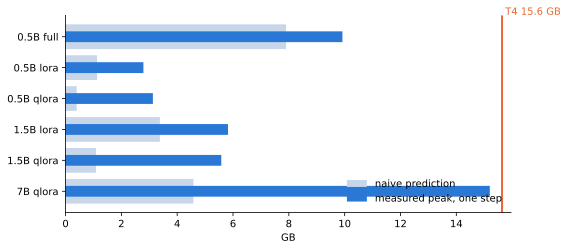

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ok = mem[mem.status == "fits"].reset_index(drop=True)
labels = [f"{m.replace('Qwen2.5-', '').replace('-Instruct', '')} {k}" for m, k in zip(ok.model, ok.method)]
ax.barh(labels, ok["predicted"], color="#c8d6ea", label="naive prediction")
ax.barh(labels, ok["peak"], height=0.35, color="#2a78d6", label="measured peak, one step")
ax.axvline(GPU_GB, color="#eb6834", lw=2)
ax.text(GPU_GB, -0.8, f" T4 {GPU_GB:.1f} GB", color="#eb6834", va="center")
ax.set_xlabel("GB")
ax.invert_yaxis()
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 3. What does our language cost?

A tokenizer splits text into the units the model reads. A bigger vocabulary usually means fewer tokens for the same
text, which means shorter sequences (less activation memory, more fits in the context window, lower cost per
request), but a bigger embedding matrix, which is the memory found in section 2. The same six support messages, in
four languages, through seven tokenizers. Llama and Gemma tokenizers are read from public mirrors of the same files.

In [8]:
SENTENCES = {
    "English": ["My card was charged twice for the same purchase.", "When will my new card arrive?",
                "I want to cancel the transfer I made this morning.", "Why was my payment declined at the shop?",
                "Please help me reset my online banking password.", "The exchange rate on my last transaction looks wrong."],
    "Hindi": ["एक ही खरीदारी के लिए मेरे कार्ड से दो बार पैसे कट गए।", "मेरा नया कार्ड कब आएगा?",
              "मैं आज सुबह किया गया ट्रांसफर रद्द करना चाहता हूँ।", "दुकान पर मेरा भुगतान क्यों अस्वीकार हो गया?",
              "कृपया मेरा ऑनलाइन बैंकिंग पासवर्ड रीसेट करने में मदद करें।", "मेरे पिछले लेनदेन की विनिमय दर गलत लग रही है।"],
    "Spanish": ["Me cobraron dos veces en la tarjeta por la misma compra.", "¿Cuándo llegará mi nueva tarjeta?",
                "Quiero cancelar la transferencia que hice esta mañana.", "¿Por qué rechazaron mi pago en la tienda?",
                "Por favor, ayúdenme a restablecer mi contraseña de banca en línea.",
                "El tipo de cambio de mi última transacción parece incorrecto."],
    "Chinese": ["同一笔消费，我的卡被扣了两次款。", "我的新卡什么时候到？", "我想取消今天早上的转账。",
                "为什么我在商店的付款被拒绝了？", "请帮我重置网上银行密码。", "我上一笔交易的汇率好像不对。"],
}
TOKENIZERS = {
    "GPT-2": "openai-community/gpt2", "SmolLM2": "HuggingFaceTB/SmolLM2-1.7B-Instruct",
    "Mistral v0.3": "mistralai/Mistral-7B-Instruct-v0.3", "Llama 3.2": "unsloth/Llama-3.2-1B-Instruct",
    "Qwen2.5": "Qwen/Qwen2.5-0.5B-Instruct", "Phi-4-mini": "microsoft/Phi-4-mini-instruct",
    "Gemma 3": "unsloth/gemma-3-1b-it",
}
counts = {}
for name, mid in TOKENIZERS.items():
    t = AutoTokenizer.from_pretrained(mid)
    counts[name] = {"vocab": len(t), **{lang: sum(len(t(s, add_special_tokens=False)["input_ids"]) for s in ss)
                                       for lang, ss in SENTENCES.items()}}
tokens = pd.DataFrame(counts).T
ratio = tokens[list(SENTENCES)].div(tokens["English"], axis=0).round(2)
print("Tokens for the six messages:")
print(tokens.to_string())
print("\nTokens relative to the same tokenizer's English:")
print(ratio.to_string())

Tokens for the six messages:
               vocab  English  Hindi  Spanish  Chinese
GPT-2          50257       56    420      120      167
SmolLM2        49152       56    296      117      142
Mistral v0.3   32768       56    286      104       85
Llama 3.2     128256       56    143       85       65
Qwen2.5       151665       56    252       85       51
Phi-4-mini    200029       56     87       71       62
Gemma 3       262145       56     68       71       54

Tokens relative to the same tokenizer's English:
              English  Hindi  Spanish  Chinese
GPT-2             1.0   7.50     2.14     2.98
SmolLM2           1.0   5.29     2.09     2.54
Mistral v0.3      1.0   5.11     1.86     1.52
Llama 3.2         1.0   2.55     1.52     1.16
Qwen2.5           1.0   4.50     1.52     0.91
Phi-4-mini        1.0   1.55     1.27     1.11
Gemma 3           1.0   1.21     1.27     0.96


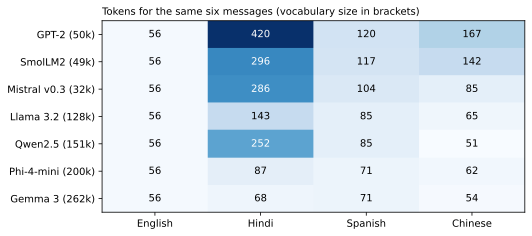

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
data = tokens[list(SENTENCES)].values
im = ax.imshow(data, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(SENTENCES)), list(SENTENCES))
ax.set_yticks(range(len(tokens)), [f"{n} ({v // 1000}k)" for n, v in zip(tokens.index, tokens.vocab)])
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        ax.text(j, i, int(data[i, j]), ha="center", va="center", color="white" if data[i, j] > data.max() * 0.55 else "black")
ax.set_title("Tokens for the same six messages (vocabulary size in brackets)", fontsize=10, loc="left")
plt.tight_layout()
plt.show()

The same reasoning sets serving memory. At inference each generated token keeps its keys and values for every layer
(the *KV cache*): $2 \times \text{layers} \times \text{KV heads} \times \text{head size} \times 2$ bytes in 16-bit.
Grouped-query attention (fewer KV heads than query heads) is why modern models keep this small.

In [10]:
kv = []
for mid in ["Qwen/Qwen2.5-0.5B-Instruct", "Qwen/Qwen2.5-1.5B-Instruct", "Qwen/Qwen2.5-7B-Instruct",
            "mistralai/Mistral-7B-Instruct-v0.3", "HuggingFaceTB/SmolLM2-1.7B-Instruct"]:
    c = AutoConfig.from_pretrained(mid)
    head = c.hidden_size // c.num_attention_heads
    per_token = 2 * c.num_hidden_layers * c.num_key_value_heads * head * 2
    kv.append({"model": mid.split("/")[1], "layers": c.num_hidden_layers, "KV heads": c.num_key_value_heads,
               "query heads": c.num_attention_heads, "KB per token": round(per_token / 1024, 1),
               "GB for 8,192 tokens": round(per_token * 8192 / GB, 2)})
print(pd.DataFrame(kv).to_string(index=False))

                   model  layers  KV heads  query heads  KB per token  GB for 8,192 tokens
   Qwen2.5-0.5B-Instruct      24         2           14          12.0                 0.10
   Qwen2.5-1.5B-Instruct      28         2           12          28.0                 0.23
     Qwen2.5-7B-Instruct      28         4           28          56.0                 0.47
Mistral-7B-Instruct-v0.3      32         8           32         128.0                 1.07
   SmolLM2-1.7B-Instruct      24        32           32         192.0                 1.61


## 4. Is it good enough, and fast enough?

The last question needs your task. Score each candidate on held-out examples **before any training**, with the
strongest prompt from lesson 1 (ten retrieved, labelled examples), and time it. BANKING77 stands in for your task
here: 385 test messages, five per intent. The 7B model runs in 4-bit, the only way it fits this GPU.

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

BASE = ("https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/"
        "9d081458ff52e53cf7e848f414e6e9344e4e6696/banking_data/")
train = pd.read_csv(BASE + "train.csv")
test = pd.read_csv(BASE + "test.csv")
LABELS = sorted(train["category"].unique())
BY_LOWER = {l.lower(): l for l in LABELS}
sample = test.groupby("category").sample(5, random_state=0).reset_index(drop=True)
vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(train["text"])
nn = cosine_similarity(vec.transform(sample["text"]), vec.transform(train["text"])).argsort(axis=1)[:, ::-1][:, :10]
SYSTEM = "You label online banking customer messages. Reply with the intent name only."
PROMPTS = [f"Intents: {', '.join(LABELS)}\n\nExamples:\n" +
           "\n".join(f"Message: {train['text'][j]}\nIntent: {train['category'][j]}" for j in idx[::-1]) +
           f"\n\nMessage: {t}\nIntent:" for t, idx in zip(sample["text"], nn)]


def parse(a):
    first = a.strip().splitlines()[0] if a.strip() else ""
    return BY_LOWER.get(re.sub(r"[^a-z_ ]", "", first.lower()).strip().replace(" ", "_"))


@torch.inference_mode()
def probe(model_id, four_bit=False, batch=8):
    cleanup()
    tok = AutoTokenizer.from_pretrained(model_id, padding_side="left")
    kw = {"quantization_config": BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                                     bnb_4bit_compute_dtype=torch.float16)} if four_bit else {"torch_dtype": torch.float16}
    model = AutoModelForCausalLM.from_pretrained(model_id, device_map={"": 0}, **kw).eval()
    model.generation_config.update(temperature=None, top_p=None, top_k=None)
    answers, start = [], time.perf_counter()
    for i in range(0, len(PROMPTS), batch):
        texts = [tok.apply_chat_template([{"role": "system", "content": SYSTEM}, {"role": "user", "content": p}],
                                         tokenize=False, add_generation_prompt=True) for p in PROMPTS[i:i + batch]]
        enc = tok(texts, return_tensors="pt", padding=True).to("cuda")
        out = model.generate(**enc, max_new_tokens=12, do_sample=False, pad_token_id=tok.eos_token_id)
        answers += tok.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    secs = time.perf_counter() - start
    parsed = [parse(a) for a in answers]
    res = {"model": model_id.split("/")[1] + (" (4-bit)" if four_bit else ""),
           "accuracy": round(sum(p == g for p, g in zip(parsed, sample["category"])) / len(sample), 3),
           "not an intent": round(sum(p is None for p in parsed) / len(sample), 3),
           "ms per message": round(1000 * secs / len(sample), 1),
           "memory (GB)": round(torch.cuda.max_memory_allocated() / GB, 2)}
    del model
    cleanup()
    print(res)
    return res


quality = pd.DataFrame([probe("Qwen/Qwen2.5-0.5B-Instruct", batch=16), probe("Qwen/Qwen2.5-1.5B-Instruct", batch=16),
                        probe("Qwen/Qwen2.5-7B-Instruct", four_bit=True, batch=8)])
print(quality.to_string(index=False))

{'model': 'Qwen2.5-0.5B-Instruct', 'accuracy': 0.657, 'not an intent': 0.034, 'ms per message': 58.1, 'memory (GB)': 1.88}


{'model': 'Qwen2.5-1.5B-Instruct', 'accuracy': 0.73, 'not an intent': 0.07, 'ms per message': 176.5, 'memory (GB)': 4.76}


{'model': 'Qwen2.5-7B-Instruct (4-bit)', 'accuracy': 0.901, 'not an intent': 0.018, 'ms per message': 706.4, 'memory (GB)': 7.59}
                      model  accuracy  not an intent  ms per message  memory (GB)
      Qwen2.5-0.5B-Instruct     0.657          0.034            58.1         1.88
      Qwen2.5-1.5B-Instruct     0.730          0.070           176.5         4.76
Qwen2.5-7B-Instruct (4-bit)     0.901          0.018           706.4         7.59


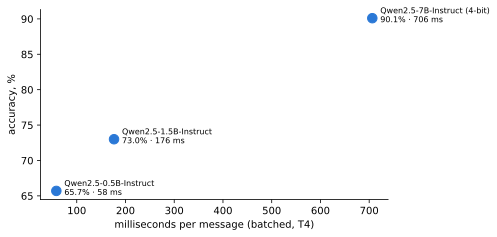

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.scatter(quality["ms per message"], quality["accuracy"] * 100, s=90, color="#2a78d6", zorder=3)
for _, r in quality.iterrows():
    ax.annotate(f"{r['model']}\n{r['accuracy'] * 100:.1f}% · {r['ms per message']:.0f} ms",
                (r["ms per message"], r["accuracy"] * 100), textcoords="offset points", xytext=(8, -4), fontsize=8)
ax.set_xlabel("milliseconds per message (batched, T4)")
ax.set_ylabel("accuracy, %")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 5. The decision, in one table

Each question removes candidates. Put the answers side by side and choose the smallest model that passes every gate
for your constraints.

In [13]:
fit = mem.set_index(["model", "method"])["status"]
licence = meta.set_index("model")["licence"]
decision = pd.DataFrame({"model": ["Qwen2.5-0.5B-Instruct", "Qwen2.5-1.5B-Instruct", "Qwen2.5-3B-Instruct", "Qwen2.5-7B-Instruct"]})
decision["licence"] = [licence.get(m) for m in decision["model"]]
decision["LoRA on this GPU"] = [fit.get((m, "lora"), "not measured") for m in decision["model"]]
decision["QLoRA on this GPU"] = [fit.get((m, "qlora"), "not measured") for m in decision["model"]]
q = quality.assign(model=quality["model"].str.replace(" (4-bit)", "", regex=False)).set_index("model")
decision["accuracy before training"] = [q["accuracy"].get(m) for m in decision["model"]]
decision["ms per message"] = [q["ms per message"].get(m) for m in decision["model"]]
print(decision.to_string(index=False))

                model       licence LoRA on this GPU QLoRA on this GPU  accuracy before training  ms per message
Qwen2.5-0.5B-Instruct    apache-2.0             fits              fits                     0.657            58.1
Qwen2.5-1.5B-Instruct    apache-2.0             fits              fits                     0.730           176.5
  Qwen2.5-3B-Instruct qwen-research     not measured      not measured                       NaN             NaN
  Qwen2.5-7B-Instruct    apache-2.0    out of memory              fits                     0.901           706.4


## 6. The template comes with the model

One more property is fixed by the base model: its chat template, the exact text that marks system, user and
assistant turns. Training data must be written in it, which is where lesson 3 starts.

In [14]:
chat = [{"role": "system", "content": "You are a bank's assistant."},
        {"role": "user", "content": "When will my card arrive?"},
        {"role": "assistant", "content": "Within five working days."}]
for mid in ["Qwen/Qwen2.5-0.5B-Instruct", "mistralai/Mistral-7B-Instruct-v0.3", "microsoft/Phi-4-mini-instruct"]:
    t = AutoTokenizer.from_pretrained(mid)
    print(f"--- {mid.split('/')[1]}")
    print(t.apply_chat_template(chat, tokenize=False))

--- Qwen2.5-0.5B-Instruct
<|im_start|>system
You are a bank's assistant.<|im_end|>
<|im_start|>user
When will my card arrive?<|im_end|>
<|im_start|>assistant
Within five working days.<|im_end|>



--- Mistral-7B-Instruct-v0.3
<s>[INST] When will my card arrive?[/INST] Within five working days.</s>


--- Phi-4-mini-instruct
<|system|>You are a bank's assistant.<|end|><|user|>When will my card arrive?<|end|><|assistant|>Within five working days.<|end|><|endoftext|>


## Read the result

- **Licence first.** It can rule out a model before any GPU time is spent, and it varies inside one family.
- **The memory rule is a floor, not a forecast.** Weights, gradients and optimizer state follow bytes per parameter;
  activations and the layers a recipe keeps in higher precision come on top, and a large vocabulary makes the second
  one large.
- **Tokens are a cost.** The same message can take several times more tokens in another language, which multiplies
  activation memory, context use and price.
- **Measure capability before training,** on your own held-out examples, and weigh it against speed.

The lesson explains each result and shows how companies made the same choice:
[Choose a base model that fits](https://docs.recohut.com/courses/llm-fine-tuning/1-decide/02-choose-a-base-model).